<a href="https://colab.research.google.com/github/mhossain-ibm/Quantum-Heckathon-26-QMinds-QFDMF/blob/main/QSVM_Fraud_Detection_IBM_Quantum_QSVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛡️ Case Study 4 · Option A — on a real IBM quantum computer
# Classifying mobile-money fraud with a QSVM and a quantum kernel

**Track:** Financial Inclusion & Resilient Markets

In this notebook a **real IBM quantum computer** measures how similar two transactions are (the *quantum
kernel*). A classical Support Vector Machine (SVM) then uses those similarities to separate **fraud** from
**normal** transactions. We compare it, fairly, against the classical **RBF-kernel SVM**.

### What we deliver (from the brief)
| Brief asks for | Where in this notebook |
|---|---|
| Quantum vs classical RBF-kernel comparison: **accuracy, precision / recall** (+ runtime) | Step 9 |
| A **fair, reproducible** dataset split | Step 3 |
| Feature map, quantum kernel, QSVM; **PCA to fit the qubit budget** | Steps 4–8 |
| An **honest note on limits** + **3-minute pitch** | Step 10 |

### Three ways to run it (set `RUN_MODE` in Step 1)
| `RUN_MODE` | Runs on | Needs API key? | Cost |
|---|---|---|---|
| `"local"` | Fake IBM device on your laptop (copies IBM's real noise) | No | Free — **test here first** |
| `"ibm"` | A **real IBM quantum computer** in the cloud | **Yes** | Uses your QPU minutes |

> ✅ Tip: run the whole notebook once with `RUN_MODE = "local"`. When it works, switch to `"ibm"`.

## 🔑 Before you start: get your IBM Quantum API key
1. Sign in at **https://quantum.cloud.ibm.com** (free *Open Plan* gives a monthly allowance of QPU time).
2. On the dashboard, create/copy your **API key**.
3. (Optional) Copy your **instance CRN** if you have more than one instance.
4. Never paste your key into a notebook you will share — this notebook asks for it with a hidden prompt, or
   reads it from the environment variable `IBM_QUANTUM_API_KEY`.

## Step 0 · Install and import

In [17]:
# Run once (remove the # to install):
%pip install qiskit qiskit-ibm-runtime qiskit-aer scikit-learn matplotlib pandas numpy

In [18]:
%pip install qiskit-machine-learning

In [19]:
import os, time
from getpass import getpass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

import qiskit, qiskit_ibm_runtime
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2

print("qiskit", qiskit.__version__, "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)

qiskit 2.6.2 | qiskit-ibm-runtime 0.52.1


## Step 1 · Settings — the only cell you need to edit

**Why so few transactions?** The kernel needs one circuit **per pair** of transactions:
- train vs train: `N_train × (N_train − 1) / 2` circuits
- test vs train: `N_test × N_train` circuits

With 30 train + 20 test that is 435 + 600 = **1,035 circuits**. Real QPU time is limited, so we keep the
sample small. Increase it if you have more QPU time.

In [20]:
RUN_MODE = "local"        # "local" = free noisy simulation of an IBM device | "ibm" = real quantum computer

# --- IBM Quantum account (only used when RUN_MODE = "ibm") ---
IBM_INSTANCE = ""          # optional: your instance CRN; leave "" to let IBM pick
BACKEND_NAME = ""          # optional: e.g. "ibm_fez"; leave "" to use the least busy device

# --- Problem size ---
N_FRAUD, N_LEGIT = 15, 35  # 50 transactions in total (30% fraud)
TEST_SIZE = 0.40           # → 30 train, 20 test
N_QUBITS  = 4              # qubit budget = number of PCA features
REPS      = 2              # how many times the feature-map pattern repeats
SHOTS     = 512            # repetitions per circuit on the quantum computer

SEED = 42                  # one number controls all randomness → reproducible results
np.random.seed(SEED)

n_train = int(round((N_FRAUD + N_LEGIT) * (1 - TEST_SIZE)))
n_test  = (N_FRAUD + N_LEGIT) - n_train
n_circ  = n_train * (n_train - 1) // 2 + n_test * n_train
print(f"Mode: {RUN_MODE} | {n_train} train, {n_test} test | {n_circ} kernel circuits x {SHOTS} shots")

Mode: local | 30 train, 20 test | 1035 kernel circuits x 512 shots


## Step 2 · Create a mobile-money transaction dataset

Real fraud data is private, so we generate a realistic synthetic dataset (inspired by the PaySim mobile-money
simulator). Each row is a transaction with 9 features; fraudsters tend to send large amounts at night, empty
the account, use new accounts / new SIMs and make bursts of transactions. We add 3% label noise because real
data is messy.

> 🔁 **Real data?** Replace this cell with `df = pd.read_csv("file.csv")` (numeric features + `is_fraud` 0/1).

In [21]:
def make_mobile_money_data(n_legit=1800, n_fraud=200, seed=SEED):
    rng = np.random.default_rng(seed)

    def block(n, fraud):
        if fraud:
            amount      = rng.lognormal(8.3, 0.9, n)                         # bigger amounts
            hour        = rng.choice(24, n, p=np.r_[np.full(6, 0.09), np.full(18, 0.46 / 18)])  # night
            old_balance = amount * rng.uniform(0.9, 1.6, n)                  # sends almost everything
            age         = rng.exponential(120, n)                            # young accounts
            tx24        = rng.poisson(6, n)                                  # bursts
            new_device  = rng.binomial(1, 0.55, n)                           # SIM swap
            transfer    = rng.binomial(1, 0.85, n)
        else:
            amount      = rng.lognormal(7.0, 1.0, n)
            hour        = rng.choice(24, n, p=np.r_[np.full(6, 0.02), np.full(18, 0.88 / 18)])
            old_balance = amount * rng.uniform(1.0, 12.0, n)
            age         = rng.exponential(700, n)
            tx24        = rng.poisson(2.5, n)
            new_device  = rng.binomial(1, 0.12, n)
            transfer    = rng.binomial(1, 0.40, n)
        return pd.DataFrame({
            "amount": amount, "hour": hour, "old_balance": old_balance,
            "new_balance": np.clip(old_balance - amount, 0, None),
            "frac_of_balance": amount / old_balance, "account_age_days": age,
            "tx_last_24h": tx24, "new_device": new_device,
            "is_transfer_or_cashout": transfer, "is_fraud": int(fraud)})

    df = pd.concat([block(n_legit, False), block(n_fraud, True)], ignore_index=True)
    flip = rng.random(len(df)) < 0.03                       # 3% label noise
    df.loc[flip, "is_fraud"] = 1 - df.loc[flip, "is_fraud"]
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)

df = make_mobile_money_data()
print(f"{len(df)} transactions, fraud rate {df.is_fraud.mean():.1%}")
df.head()

2000 transactions, fraud rate 12.0%


,amount,hour,old_balance,new_balance,frac_of_balance,account_age_days,tx_last_24h,new_device,is_transfer_or_cashout,is_fraud
0,947.457660,1,890.820082,0.000000,1.063579,86.789519,6,1,1,1
1,2474.425904,8,11719.591492,9245.165588,0.211136,1286.399515,3,0,0,0
2,1436.687556,0,14267.308091,12830.620536,0.100698,214.867957,2,0,1,0
3,8606.716541,8,15280.231649,6673.515109,0.563258,58.650502,2,1,0,0
4,2500.384052,18,19856.323855,17355.939803,0.125924,918.348656,4,0,0,0


## Step 3 · A fair, reproducible split

1. Take a fixed, small sample (15 fraud + 35 normal).
2. **Stratified** train/test split — both parts keep the same fraud share.
3. Fixed `SEED` — everyone who runs this gets the same rows.
4. Both models use **exactly** the same train and test rows.

In [22]:
sample = pd.concat([
    df[df.is_fraud == 1].sample(N_FRAUD, random_state=SEED),
    df[df.is_fraud == 0].sample(N_LEGIT, random_state=SEED),
]).sample(frac=1, random_state=SEED).reset_index(drop=True)

for col in ["amount", "old_balance", "new_balance", "account_age_days"]:   # tame skewed money values
    sample[col] = np.log1p(sample[col])

X = sample.drop(columns="is_fraud").values
y = sample["is_fraud"].values

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)

print(f"Train: {len(y_train)} rows, {y_train.sum()} fraud | Test: {len(y_test)} rows, {y_test.sum()} fraud")

Train: 30 rows, 9 fraud | Test: 20 rows, 6 fraud


## Step 4 · PCA: 9 features → 4 qubits

One qubit per feature, and we only want 4 qubits. **PCA** compresses the 9 features into 4 summary features.
Then we scale them into `[0, π]` because they become **rotation angles** on the qubits.

⚠️ Every transformer is **fitted on the training rows only** (no peeking at the test set).

In [23]:
scaler = StandardScaler().fit(X_train_raw)
pca    = PCA(n_components=N_QUBITS, random_state=SEED).fit(scaler.transform(X_train_raw))
angles = MinMaxScaler((0, np.pi)).fit(pca.transform(scaler.transform(X_train_raw)))

def prepare(X_raw):
    return np.clip(angles.transform(pca.transform(scaler.transform(X_raw))), 0, np.pi)

X_train, X_test = prepare(X_train_raw), prepare(X_test_raw)
print(f"Information kept by {N_QUBITS} PCA features: {pca.explained_variance_ratio_.sum():.1%}")

Information kept by 4 PCA features: 81.7%


## Step 5 · The feature map and the fidelity circuit

We use Qiskit's **ZZ feature map** with **linear** entanglement (each qubit is linked only to its neighbour).
Linear needs fewer two-qubit gates than linking every pair, which matters on real hardware: every extra gate
adds noise.

The **fidelity circuit** is `U(x)` followed by `U(y)†`, then a measurement of all qubits.

In [24]:
feature_map_x = zz_feature_map(N_QUBITS, reps=REPS, entanglement="linear", parameter_prefix="x")
feature_map_y = zz_feature_map(N_QUBITS, reps=REPS, entanglement="linear", parameter_prefix="y")

fidelity_circuit = feature_map_x.compose(feature_map_y.inverse())   # U(x) then U(y)†
fidelity_circuit.measure_all()

print("Feature map U(x):")
print(feature_map_x.draw(output="text", fold=140))
print("\nParameters of the fidelity circuit (x = first transaction, y = second):")
print([p.name for p in fidelity_circuit.parameters])

Feature map U(x):
   ┌───┐┌───────────┐                                          ┌───┐         ┌───────────┐                    »
0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■──┤ H ├─────────┤ P(2*x[0]) ├────────────────────»
   ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐└───┘         └───────────┘               ┌───┐»
1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├──■────────────────────────────────────■──┤ H ├»
   ├───┤├───────────┤└───┘└──────────────────────────────┘└───┘┌─┴─┐┌──────────────────────────────┐┌─┴─┐└───┘»
2: ┤ H ├┤ P(2*x[2]) ├──────────────────────────────────────────┤ X ├┤ P((-π + x[1])*(-π + x[2])*2) ├┤ X ├──■──»
   ├───┤├───────────┤                                          └───┘└──────────────────────────────┘└───┘┌─┴─┐»
3: ┤ H ├┤ P(2*x[3]) ├────────────────────────────────────────────────────────────────────────────────────┤ X ├»
   └───┘└───────────┘                                                                 

## Step 6 · Tune the kernel on a free, exact simulator

Before spending QPU time we pick the model settings on the laptop, using **only the training data** and
3-fold cross-validation:
- **bandwidth `b`** — features are multiplied by `b` before entering the circuit. Small `b` = smoother kernel.
  (Without it, every transaction looks totally different from every other one and the SVM just memorises.)
- **`C`** — how strongly the SVM punishes training mistakes.

The exact simulator computes `|⟨ψ(a)|ψ(b)⟩|²` directly from the statevector, with no noise. The real
quantum computer will later compute the same numbers by measurement.

In [25]:
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# 1. Replace def exact_kernel(XA, XB) with Qiskit's statevector kernel
quantum_kernel = FidelityStatevectorKernel(feature_map=feature_map_x)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
C_GRID = [0.1, 1, 10, 100]
BANDWIDTHS = [0.1, 0.2, 0.3, 0.5, 1.0]

best = {"score": -1}

for b in BANDWIDTHS:
    # 2. Initialize QSVC with the quantum kernel (supports all standard SVC params)
    qsvc = QSVC(quantum_kernel=quantum_kernel, class_weight="balanced")

    # 3. Pass the scaled training data (X_train * b) directly into GridSearchCV
    search = GridSearchCV(
        estimator=qsvc,
        param_grid={"C": C_GRID},
        scoring="f1",
        cv=cv
    ).fit(X_train * b, y_train)

    print(f"bandwidth {b:<4} → best C = {search.best_params_['C']:<5} cross-validated F1 = {search.best_score_:.3f}")
    if search.best_score_ > best["score"]:
        best = {"score": search.best_score_, "b": b, "C": search.best_params_["C"]}

BW, C_Q = best["b"], best["C"]
print(f"\nChosen for the QSVM: bandwidth = {BW}, C = {C_Q}")

# 4. Fit your final QSVC model using the chosen bandwidth and C
final_qsvc = QSVC(quantum_kernel=quantum_kernel, C=C_Q, class_weight="balanced")
final_qsvc.fit(X_train * BW, y_train)

# Predict on test data (remembering to scale X_test by BW)
y_pred = final_qsvc.predict(X_test * BW)

bandwidth 0.1  → best C = 10    cross-validated F1 = 0.850
bandwidth 0.2  → best C = 10    cross-validated F1 = 0.683
bandwidth 0.3  → best C = 1     cross-validated F1 = 0.819
bandwidth 0.5  → best C = 10    cross-validated F1 = 0.111
bandwidth 1.0  → best C = 1     cross-validated F1 = 0.300

Chosen for the QSVM: bandwidth = 0.1, C = 10


In [26]:
# QSVM with the exact (noise-free) kernel — this is the "ideal quantum computer" reference
t0 = time.perf_counter()
K_train_exact = exact_kernel(X_train * BW, X_train * BW)
K_test_exact  = exact_kernel(X_test * BW,  X_train * BW)
qsvm_exact = SVC(kernel="precomputed", C=C_Q, class_weight="balanced").fit(K_train_exact, y_train)
y_pred_exact = qsvm_exact.predict(K_test_exact)
time_exact = time.perf_counter() - t0
print(f"Ideal QSVM done in {time_exact:.2f} s")

Ideal QSVM done in 0.72 s


## Step 7 · The classical baseline: RBF-kernel SVM

Same rows, same 4 PCA features, same `C` grid, same cross-validation. The RBF kernel tunes its own width `γ`,
just like the QSVM tuned its bandwidth.

In [27]:
t0 = time.perf_counter()
rbf_search = GridSearchCV(SVC(kernel="rbf", class_weight="balanced"),
                          {"C": C_GRID, "gamma": ["scale", 0.1, 1.0, 10.0]}, scoring="f1", cv=cv).fit(X_train, y_train)
y_pred_rbf = rbf_search.predict(X_test)
time_rbf = time.perf_counter() - t0
print("Best RBF settings:", rbf_search.best_params_, f"| {time_rbf:.2f} s")

Best RBF settings: {'C': 1, 'gamma': 'scale'} | 0.69 s


## Step 8 · Run the quantum kernel on IBM Quantum

### 8a · Connect and pick a device
- `"ibm"` → logs in with your API key and picks a real device.
- `"local"` → uses `FakeFez`, a laptop copy of IBM's 156-qubit *Heron* device, **including its noise**.

In [28]:
if RUN_MODE == "ibm":
    api_key = os.environ.get("m84Y0SEA8KC-PAm55xgAi_eRF1in8L3bCOdsxrTl3FcG") or getpass("m84Y0SEA8KC-PAm55xgAi_eRF1in8L3bCOdsxrTl3FcG")
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=api_key,
                                   instance=IBM_INSTANCE or None)
    # To avoid pasting the key every time you could save it once (stored on YOUR computer):
    # QiskitRuntimeService.save_account(channel="ibm_quantum_platform", token=api_key, overwrite=True)
    backend = (service.backend(BACKEND_NAME) if BACKEND_NAME
               else service.least_busy(operational=True, simulator=False, min_num_qubits=N_QUBITS))
else:
    from qiskit_ibm_runtime.fake_provider import FakeFez      # needs qiskit-aer
    backend = FakeFez()

print("Running on:", backend.name, f"({backend.num_qubits} qubits)")

Running on: fake_fez (156 qubits)


### 8b · Translate the circuit for the device ("transpile")
Real chips only understand a few native gates and can only link certain qubits. The transpiler rewrites our
circuit into that language and picks good physical qubits. We do it **once**; each transaction pair only
changes the numbers (parameters) fed into the same circuit.

In [29]:
pass_manager = generate_preset_pass_manager(optimization_level=1, backend=backend)
isa_circuit  = pass_manager.run(fidelity_circuit)

ops = isa_circuit.count_ops()
two_qubit = sum(n for g, n in ops.items() if g in ("cz", "ecr", "cx"))
print("Native gates used:", dict(ops))
print("Two-qubit gates (the noisiest part):", two_qubit, "| circuit depth:", isa_circuit.depth())

Native gates used: {'rz': 140, 'sx': 56, 'cz': 22, 'measure': 4, 'barrier': 1}
Two-qubit gates (the noisiest part): 22 | circuit depth: 129


### 8c · Build the jobs and send them

For every pair of transactions we put 8 numbers into the circuit: the 4 features of transaction *a*
(`x[0..3]`) and the 4 features of transaction *b* (`y[0..3]`).
- **Train kernel:** only pairs with `i < j` are run. Similarity is symmetric, and a transaction compared with
  itself is 1 by definition.
- **Test kernel:** every test transaction vs every training transaction.

On real hardware we switch on two simple noise-reduction tricks offered by IBM Runtime:
**dynamical decoupling** (protects idle qubits) and **gate twirling** (turns errors into easier-to-average noise).

⏳ On `"ibm"` the jobs wait in a queue; this cell can take from a few minutes to much longer. The job IDs are
printed so you can collect results later (see the cell after this one).

In [30]:
def make_pairs(XA, XB, symmetric):
    pairs = [(i, j) for i in range(len(XA)) for j in range(len(XB)) if (not symmetric or j > i)]
    values = np.array([np.r_[XA[i], XB[j]] for i, j in pairs])   # 8 numbers per circuit: x[0..3], y[0..3]
    return pairs, values

train_pairs, train_values = make_pairs(X_train * BW, X_train * BW, symmetric=True)
test_pairs,  test_values  = make_pairs(X_test * BW,  X_train * BW, symmetric=False)
print(f"Train-kernel circuits: {len(train_pairs)} | Test-kernel circuits: {len(test_pairs)}")

sampler = SamplerV2(mode=backend)
if RUN_MODE == "ibm":
    sampler.options.dynamical_decoupling.enable = True
    sampler.options.twirling.enable_gates = True

t0 = time.perf_counter()
# One job, two "PUBs" (circuit + many parameter sets each)
job = sampler.run([(isa_circuit, train_values), (isa_circuit, test_values)], shots=SHOTS)
print("Job ID:", job.job_id(), "— waiting for results ...")
result = job.result()
time_quantum = time.perf_counter() - t0
print(f"Done in {time_quantum:.1f} s (wall-clock, including any queue time)")

Train-kernel circuits: 435 | Test-kernel circuits: 600
Job ID: e5b8af6c-af3c-4bfa-b5b6-719c2f63fbb4 — waiting for results ...
Done in 40.0 s (wall-clock, including any queue time)


In [31]:
# ── Lost your connection? Collect a finished job later with its ID: ──
# service = QiskitRuntimeService(channel="ibm_quantum_platform")
# result  = service.job("PASTE-JOB-ID-HERE").result()

# How much real QPU time did it use? (only available for real IBM jobs)
if RUN_MODE == "ibm":
    try:
        print("QPU time used (s):", job.metrics()["usage"]["quantum_seconds"])
    except Exception as err:
        print("Usage not available yet:", err)

### 8d · Turn measurement counts into the kernel tables
`K(a, b) = (times we measured 0000) / SHOTS`

In [32]:
ZERO = "0" * N_QUBITS

def counts_to_kernel(pub_result, pairs, shape, symmetric):
    bits = pub_result.data.meas
    K = np.eye(shape[0]) if symmetric else np.zeros(shape)
    for k, (i, j) in enumerate(pairs):
        p_zero = bits.get_counts(loc=k).get(ZERO, 0) / SHOTS
        K[i, j] = p_zero
        if symmetric:
            K[j, i] = p_zero
    return K

K_train_hw = counts_to_kernel(result[0], train_pairs, (len(X_train), len(X_train)), symmetric=True)
K_test_hw  = counts_to_kernel(result[1], test_pairs,  (len(X_test),  len(X_train)), symmetric=False)

err = np.abs(K_train_hw - K_train_exact)[~np.eye(len(X_train), dtype=bool)].mean()
print(f"Average difference between hardware kernel and ideal kernel: {err:.3f}")

Average difference between hardware kernel and ideal kernel: 0.062


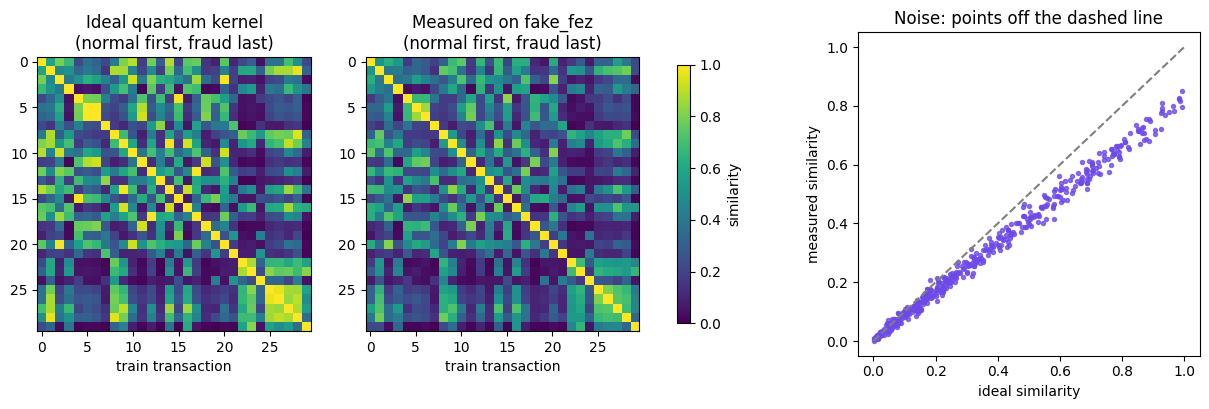

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
order = np.argsort(y_train)
for ax, K, title in [(axes[0], K_train_exact, "Ideal quantum kernel"),
                     (axes[1], K_train_hw, f"Measured on {backend.name}")]:
    im = ax.imshow(K[np.ix_(order, order)], cmap="viridis", vmin=0, vmax=1)
    ax.set_title(title + "\n(normal first, fraud last)"); ax.set_xlabel("train transaction")
fig.colorbar(im, ax=axes[:2], shrink=0.8, label="similarity")
mask = ~np.eye(len(X_train), dtype=bool)
axes[2].scatter(K_train_exact[mask], K_train_hw[mask], s=8, alpha=0.5, color="#6D4AE8")
axes[2].plot([0, 1], [0, 1], "--", color="gray")
axes[2].set_xlabel("ideal similarity"); axes[2].set_ylabel("measured similarity")
axes[2].set_title("Noise: points off the dashed line")
plt.show()

### 8e · Train and test the QSVM with the hardware kernel

In [34]:
qsvm_hw = SVC(kernel="precomputed", C=C_Q, class_weight="balanced").fit(K_train_hw, y_train)
y_pred_hw = qsvm_hw.predict(K_test_hw)
print("QSVM trained on the measured quantum kernel.")

QSVM trained on the measured quantum kernel.


## Step 9 · Quantum vs classical comparison

- **Accuracy** — share of all test transactions labelled correctly.
- **Precision** — of the transactions flagged as fraud, how many really were fraud? (low = false alarms →
  honest users get their wallet frozen)
- **Recall** — of all real fraud, how much did we catch? (low = money stolen from households)
- **F1** — one number balancing precision and recall.

In [35]:
def scores(y_pred, seconds):
    return {"Accuracy":  accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall":    recall_score(y_test, y_pred),
            "F1":        f1_score(y_test, y_pred, zero_division=0),
            "Runtime (s)": seconds}

hw_label = f"QSVM · real IBM {backend.name}" if RUN_MODE == "ibm" else f"QSVM · noisy sim of {backend.name}"
results = pd.DataFrame({
    "Classical RBF SVM":   scores(y_pred_rbf,   time_rbf),
    "QSVM · ideal (simulated)": scores(y_pred_exact, time_exact),
    hw_label:              scores(y_pred_hw,    time_quantum),
}).T
print(f"Test set: {len(y_test)} transactions, {y_test.sum()} of them fraud")
results.round(3)

Test set: 20 transactions, 6 of them fraud


,Accuracy,Precision,Recall,F1,Runtime (s)
Classical RBF SVM,0.90,1.0,0.667,0.800,0.691
QSVM · ideal (simulated),0.85,1.0,0.500,0.667,0.724
QSVM · noisy sim of fake_fez,0.85,1.0,0.500,0.667,39.954


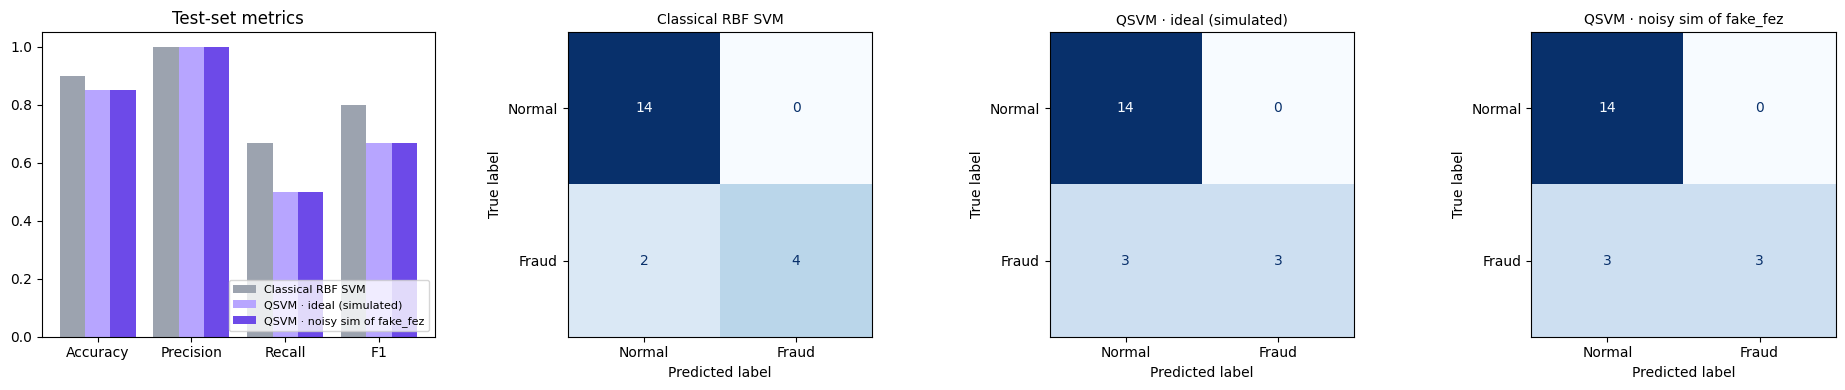

In [36]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
metrics = ["Accuracy", "Precision", "Recall", "F1"]
colours = ["#9CA3AF", "#B7A5FF", "#6D4AE8"]
xpos = np.arange(len(metrics)); w = 0.27
for k, (name, row) in enumerate(results.iterrows()):
    axes[0].bar(xpos + (k - 1) * w, row[metrics], w, label=name, color=colours[k])
axes[0].set_xticks(xpos, metrics); axes[0].set_ylim(0, 1.05); axes[0].legend(fontsize=8, loc="lower right")
axes[0].set_title("Test-set metrics")
for ax, pred, name in zip(axes[1:], [y_pred_rbf, y_pred_exact, y_pred_hw], results.index):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Normal", "Fraud"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

**How to read this:** with only 20 test transactions (6 fraud), catching one more or one fewer fraud case moves
recall by ~17 points. Treat small differences as **ties**. The most informative comparison is
*ideal QSVM vs hardware QSVM*: the gap between them is the price of today's hardware noise.

> ⏱️ **Runtime note:** the hardware runtime includes queue waiting and network time, so it is not a measure of
> how fast the quantum chip itself is. Use the QPU time printed in Step 8c for that.